# Banking & Financial Risk Analytics
## Exploratory Data Analysis (EDA) - Home Credit Default Risk

This notebook provides the exploratory data analysis environment for analyzing financial default risk across credit applicant profiles, credit bureau records, and repayment histories.

In [ ]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [20]:
# ============================================================
# BANKING & FINANCIAL RISK ANALYTICS
# PHASE 1: DATA EXPLORATION AND INITIAL KPI ANALYSIS
# Dataset: Home Credit Default Risk
# ============================================================


# ============================================================
# 1. IMPORT REQUIRED LIBRARIES
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path


# ============================================================
# 2. LOAD DATASET
# ============================================================

# Locate dataset from project root or python directory

possible_paths = [
    Path("datasets/raw/home-credit-default-risk/application_train.csv"),
    Path("../datasets/raw/home-credit-default-risk/application_train.csv")
]

file_path = next(
    (path for path in possible_paths if path.exists()),
    None
)

if file_path is None:
    raise FileNotFoundError(
        "application_train.csv not found. Check your dataset path."
    )

df = pd.read_csv(file_path)

print("\n" + "=" * 60)
print("BANKING FINANCIAL RISK ANALYTICS")
print("=" * 60)

print("\nDataset Loaded Successfully!")


# ============================================================
# 3. DATA UNDERSTANDING
# ============================================================

print("\n--- FIRST 5 RECORDS ---")
print(df.head())

print("\n--- DATASET DIMENSIONS ---")
print(f"Total Rows: {df.shape[0]}")
print(f"Total Columns: {df.shape[1]}")

print("\n--- DATASET INFORMATION ---")
df.info()

print("\n--- COLUMN NAMES ---")
print(df.columns.tolist())


# ============================================================
# 4. MISSING VALUE ANALYSIS
# ============================================================

print("\n--- MISSING VALUE ANALYSIS ---")

missing_values = df.isnull().sum()

missing_percentage = (
    df.isnull().mean() * 100
)

missing_report = pd.DataFrame({
    "Missing Count": missing_values,
    "Missing Percentage": missing_percentage
})

missing_report = missing_report[
    missing_report["Missing Count"] > 0
].sort_values(
    by="Missing Percentage",
    ascending=False
)

print(missing_report.head(20))


# ============================================================
# 5. STATISTICAL ANALYSIS
# ============================================================

print("\n--- STATISTICAL SUMMARY ---")

print(df.describe().T)


# ============================================================
# 6. DUPLICATE ANALYSIS
# ============================================================

print("\n--- DUPLICATE ANALYSIS ---")

duplicate_rows = df.duplicated().sum()

duplicate_customers = (
    df["SK_ID_CURR"].duplicated().sum()
)

print("Duplicate Rows:", duplicate_rows)

print("Duplicate Customer IDs:", duplicate_customers)


# ============================================================
# 7. DEFAULT ANALYSIS
# ============================================================

print("\n--- DEFAULT DISTRIBUTION ---")

default_distribution = df["TARGET"].value_counts(
    dropna=False
)

print(default_distribution)

total_customers = df["SK_ID_CURR"].nunique()

valid_target_count = df["TARGET"].notna().sum()

defaulted_customers = (
    df["TARGET"] == 1
).sum()

non_defaulted_customers = (
    df["TARGET"] == 0
).sum()

default_percentage = (
    defaulted_customers / valid_target_count * 100
    if valid_target_count > 0 else 0
)

print("\nDefault Percentage:",
      round(default_percentage, 2), "%")


# ============================================================
# 8. FINANCIAL KPI CALCULATIONS
# ============================================================

print("\n--- FINANCIAL KPI ANALYSIS ---")

average_income = df["AMT_INCOME_TOTAL"].mean()

average_credit = df["AMT_CREDIT"].mean()

missing_income = df["AMT_INCOME_TOTAL"].isnull().sum()

average_age = (
    -df["DAYS_BIRTH"] / 365.25
).mean()


# ============================================================
# 9. CREATE KPI REPORT
# ============================================================

kpi_report = pd.DataFrame({

    "Metric": [

        "Total Customers",

        "Defaulted Customers",

        "Non-Defaulted Customers",

        "Default Percentage",

        "Average Annual Income",

        "Average Credit Amount",

        "Customers With Missing Income",

        "Duplicate Customer Records",

        "Average Customer Age"

    ],

    "Value": [

        total_customers,

        defaulted_customers,

        non_defaulted_customers,

        f"{default_percentage:.2f}%",

        f"{average_income:,.2f}",

        f"{average_credit:,.2f}",

        missing_income,

        duplicate_customers,

        f"{average_age:.2f} Years"

    ]

})


print("\n" + "=" * 60)

print("FINAL BANKING ANALYTICS KPI REPORT")

print("=" * 60)

print(kpi_report.to_string(index=False))


# ============================================================
# 10. SAVE KPI REPORT
# ============================================================

# Define base reports directory (supports execution from project root or python/ directory)
PROJECT_ROOT = file_path.parents[3] if len(file_path.parents) >= 4 else (
    Path("..") if Path("../datasets").exists() else Path(".")
)
REPORTS_DIR = PROJECT_ROOT / "reports"

REPORTS_DIR.mkdir(
    parents=True,
    exist_ok=True
)

output_directory = REPORTS_DIR

kpi_report.to_csv(
    REPORTS_DIR / "initial_kpi_report.csv",
    index=False
)

print("\nKPI Report Saved Successfully to:", REPORTS_DIR.resolve())

print("\n" + "=" * 60)
print("DATA EXPLORATION COMPLETED")
print("=" * 60)



BANKING FINANCIAL RISK ANALYTICS

Dataset Loaded Successfully!

--- FIRST 5 RECORDS ---
   SK_ID_CURR  TARGET NAME_CONTRACT_TYPE CODE_GENDER FLAG_OWN_CAR  \
0      100002       1         Cash loans           M            N   
1      100003       0         Cash loans           F            N   
2      100004       0    Revolving loans           M            Y   
3      100006       0         Cash loans           F            N   
4      100007       0         Cash loans           M            N   

  FLAG_OWN_REALTY  CNT_CHILDREN  AMT_INCOME_TOTAL  AMT_CREDIT  AMT_ANNUITY  \
0               Y             0          202500.0    406597.5      24700.5   
1               N             0          270000.0   1293502.5      35698.5   
2               Y             0           67500.0    135000.0       6750.0   
3               Y             0          135000.0    312682.5      29686.5   
4               Y             0          121500.0    513000.0      21865.5   

   ...  FLAG_DOCUMENT_18 FL

,total_customers,defaulted_customers,target_records,default_percentage
CODE_GENDER,,,,
F,202448,14170,202448,6.999328
M,105059,10655,105059,10.141920
XNA,4,0,4,0.000000


,total_customers,defaulted_customers,target_records,default_percentage
NAME_EDUCATION_TYPE,,,,
Lower secondary,3816,417,3816,10.927673
Secondary / secondary special,218391,19524,218391,8.939929
Incomplete higher,10277,872,10277,8.484966
Higher education,74863,4009,74863,5.355115
Academic degree,164,3,164,1.829268


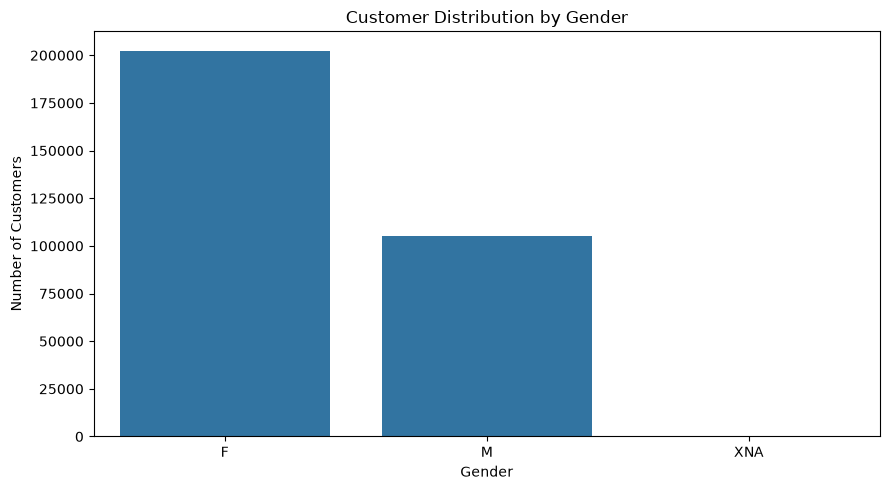

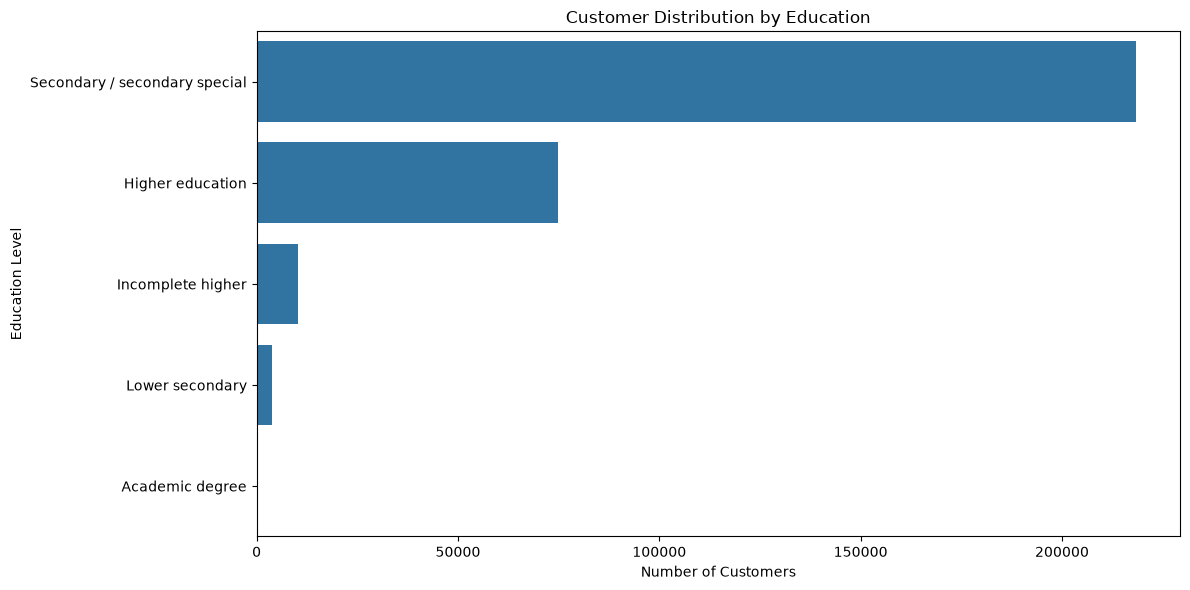

In [22]:
# Gender distribution
gender_analysis = df.groupby(
    "CODE_GENDER",
    dropna=False
).agg(
    total_customers=("SK_ID_CURR", "nunique"),
    defaulted_customers=("TARGET", "sum"),
    target_records=("TARGET", "count")
)

gender_analysis["default_percentage"] = (
    gender_analysis["defaulted_customers"]
    / gender_analysis["target_records"]
    * 100
)

display(gender_analysis)

# Education analysis
education_analysis = df.groupby(
    "NAME_EDUCATION_TYPE",
    dropna=False
).agg(
    total_customers=("SK_ID_CURR", "nunique"),
    defaulted_customers=("TARGET", "sum"),
    target_records=("TARGET", "count")
)

education_analysis["default_percentage"] = (
    education_analysis["defaulted_customers"]
    / education_analysis["target_records"]
    * 100
)

education_analysis = education_analysis.sort_values(
    by="default_percentage",
    ascending=False
)

display(education_analysis)

# Gender distribution chart
plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x="CODE_GENDER",
    order=df["CODE_GENDER"].value_counts().index
)

plt.title("Customer Distribution by Gender")
plt.xlabel("Gender")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()

# Education distribution chart
plt.figure(figsize=(12, 6))

sns.countplot(
    data=df,
    y="NAME_EDUCATION_TYPE",
    order=df["NAME_EDUCATION_TYPE"].value_counts().index
)

plt.title("Customer Distribution by Education")
plt.xlabel("Number of Customers")
plt.ylabel("Education Level")
plt.tight_layout()
plt.show()

# Save results
gender_analysis.to_csv(REPORTS_DIR / "gender_analysis.csv")
education_analysis.to_csv(REPORTS_DIR / "education_analysis.csv")


Average income: 168797.9192969845
Median income: 147150.0
Minimum income: 25650.0
Maximum income: 117000000.0


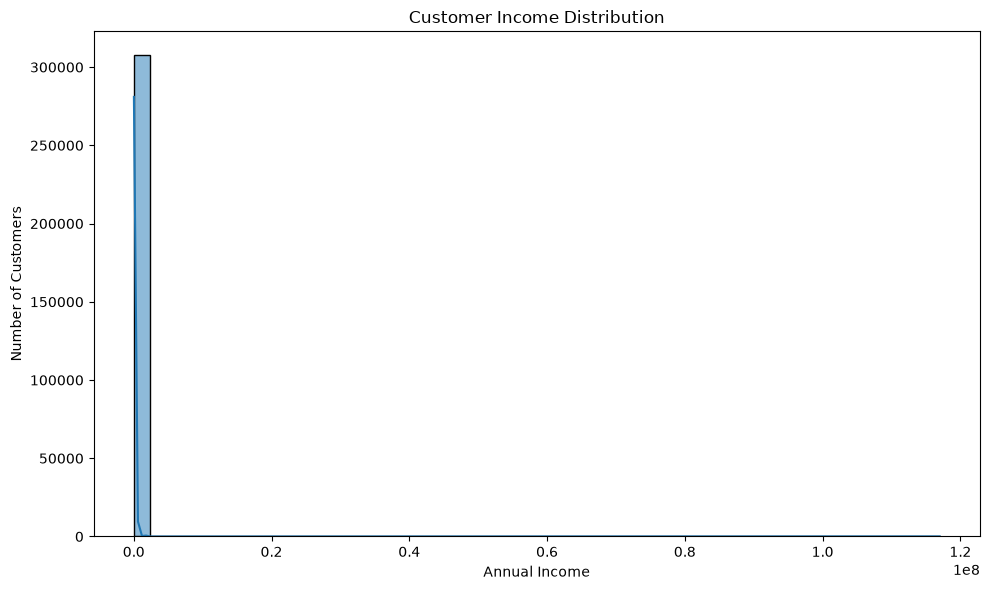

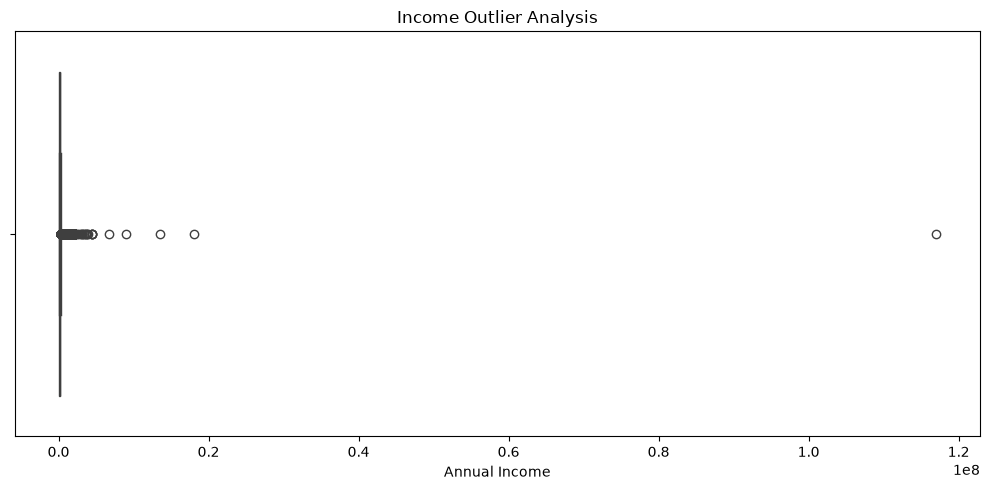

,total_customers,defaulted_customers,target_records,average_income,default_percentage
INCOME_CATEGORY,,,,,
High Income,76878,5379,76878,291508.299188,6.996800
Low Income,76878,6356,76878,83420.511321,8.267645
Lower Middle Income,76878,6624,76878,126511.345380,8.616249
Upper Middle Income,76877,6466,76877,173751.585735,8.410838


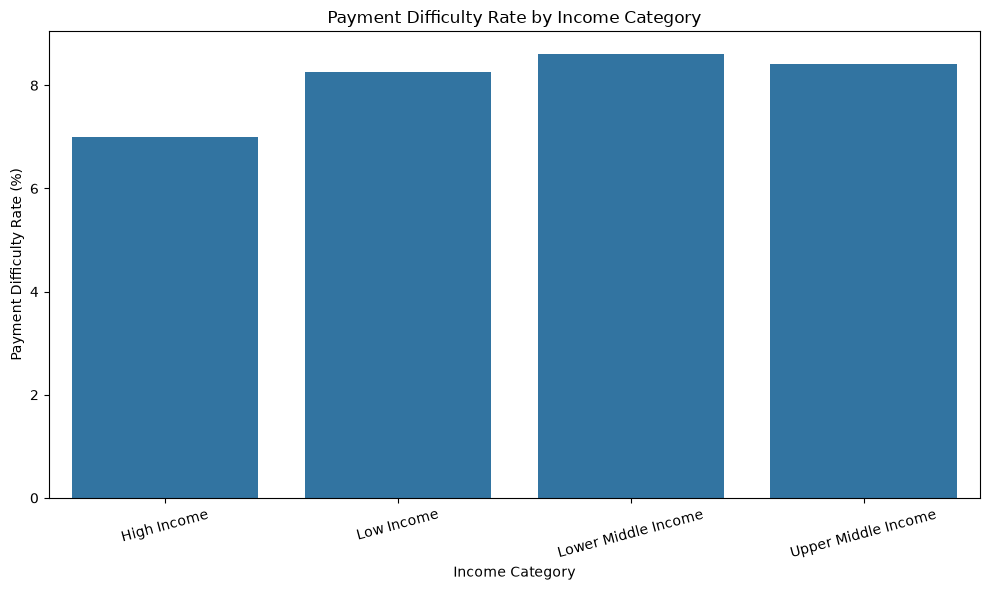

In [24]:
# Basic income statistics
print("Average income:", df["AMT_INCOME_TOTAL"].mean())
print("Median income:", df["AMT_INCOME_TOTAL"].median())
print("Minimum income:", df["AMT_INCOME_TOTAL"].min())
print("Maximum income:", df["AMT_INCOME_TOTAL"].max())

# Income distribution
plt.figure(figsize=(10, 6))

sns.histplot(
    data=df,
    x="AMT_INCOME_TOTAL",
    bins=50,
    kde=True
)

plt.title("Customer Income Distribution")
plt.xlabel("Annual Income")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()

# Boxplot to identify outliers
plt.figure(figsize=(10, 5))

sns.boxplot(x=df["AMT_INCOME_TOTAL"])

plt.title("Income Outlier Analysis")
plt.xlabel("Annual Income")
plt.tight_layout()
plt.show()

# Create income quartiles using non-missing values
income_category = pd.Series(
    index=df.index,
    dtype="object"
)

valid_income = df["AMT_INCOME_TOTAL"].notna()

income_category.loc[valid_income] = pd.qcut(
    df.loc[valid_income, "AMT_INCOME_TOTAL"].rank(method="first"),
    q=4,
    labels=[
        "Low Income",
        "Lower Middle Income",
        "Upper Middle Income",
        "High Income"
    ]
).astype("object")

df["INCOME_CATEGORY"] = income_category

# Income group analysis
income_analysis = df.groupby(
    "INCOME_CATEGORY",
    observed=True
).agg(
    total_customers=("SK_ID_CURR", "nunique"),
    defaulted_customers=("TARGET", "sum"),
    target_records=("TARGET", "count"),
    average_income=("AMT_INCOME_TOTAL", "mean")
)

income_analysis["default_percentage"] = (
    income_analysis["defaulted_customers"]
    / income_analysis["target_records"]
    * 100
)

display(income_analysis)

# Default percentage chart
plt.figure(figsize=(10, 6))

sns.barplot(
    data=income_analysis.reset_index(),
    x="INCOME_CATEGORY",
    y="default_percentage"
)

plt.title("Payment Difficulty Rate by Income Category")
plt.xlabel("Income Category")
plt.ylabel("Payment Difficulty Rate (%)")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

# Save results
income_analysis.to_csv(REPORTS_DIR / "income_analysis.csv")

Average customer age: 43.906899566990106
Minimum customer age: 20.503764544832308
Maximum customer age: 69.07323750855578


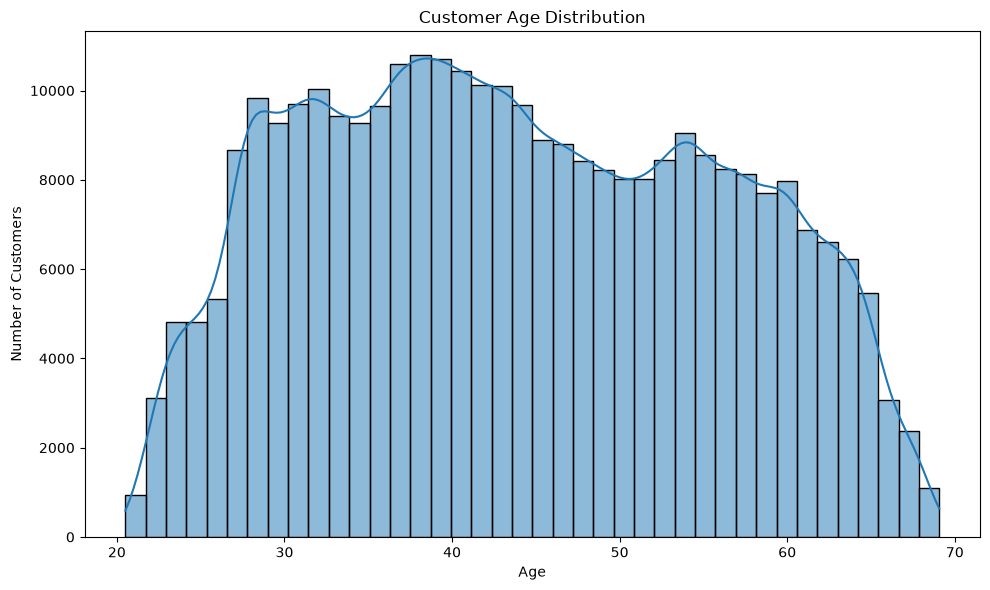

,total_customers,defaulted_customers,target_records,average_income,average_credit,default_percentage
AGE_GROUP,,,,,,
18-25,16409,1926,16409,148900.248577,428232.489975,11.737461
26-35,76007,8042,76007,173596.570813,552755.997730,10.580604
36-45,83770,6894,83770,180953.522755,645483.785759,8.229676
46-55,69462,4766,69462,173333.767931,657666.920446,6.861305
56-65,56988,3031,56988,149187.849777,601344.667009,5.318664
66+,4875,166,4875,116688.051692,234343.775077,3.405128


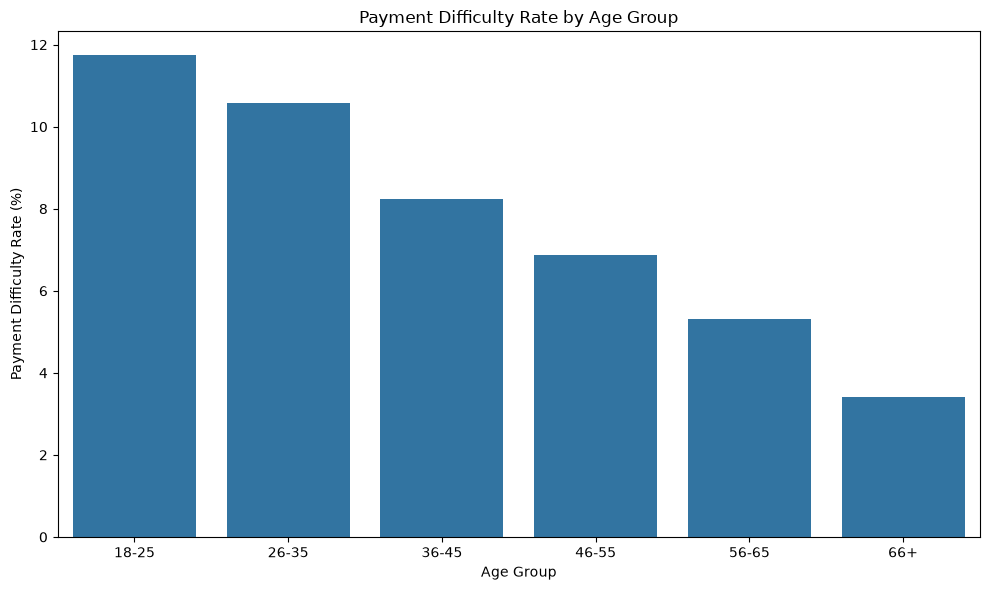

In [26]:
# Convert days into age in years
df["AGE"] = -df["DAYS_BIRTH"] / 365.25

print("Average customer age:", df["AGE"].mean())
print("Minimum customer age:", df["AGE"].min())
print("Maximum customer age:", df["AGE"].max())

# Age distribution
plt.figure(figsize=(10, 6))

sns.histplot(
    data=df,
    x="AGE",
    bins=40,
    kde=True
)

plt.title("Customer Age Distribution")
plt.xlabel("Age")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()

# Define age groups
age_bins = [18, 26, 36, 46, 56, 66, np.inf]

age_labels = [
    "18-25",
    "26-35",
    "36-45",
    "46-55",
    "56-65",
    "66+"
]

df["AGE_GROUP"] = pd.cut(
    df["AGE"],
    bins=age_bins,
    labels=age_labels,
    right=False
)

# Age group analysis
age_analysis = df.groupby(
    "AGE_GROUP",
    observed=True
).agg(
    total_customers=("SK_ID_CURR", "nunique"),
    defaulted_customers=("TARGET", "sum"),
    target_records=("TARGET", "count"),
    average_income=("AMT_INCOME_TOTAL", "mean"),
    average_credit=("AMT_CREDIT", "mean")
)

age_analysis["default_percentage"] = (
    age_analysis["defaulted_customers"]
    / age_analysis["target_records"]
    * 100
)

display(age_analysis)

# Payment difficulty by age
plt.figure(figsize=(10, 6))

sns.barplot(
    data=age_analysis.reset_index(),
    x="AGE_GROUP",
    y="default_percentage"
)

plt.title("Payment Difficulty Rate by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Payment Difficulty Rate (%)")
plt.tight_layout()
plt.show()

# Save results
age_analysis.to_csv(REPORTS_DIR / "age_analysis.csv")

Average credit: 599025.9997057016
Median credit: 513531.0
Maximum credit: 4050000.0
Minimum credit: 45000.0


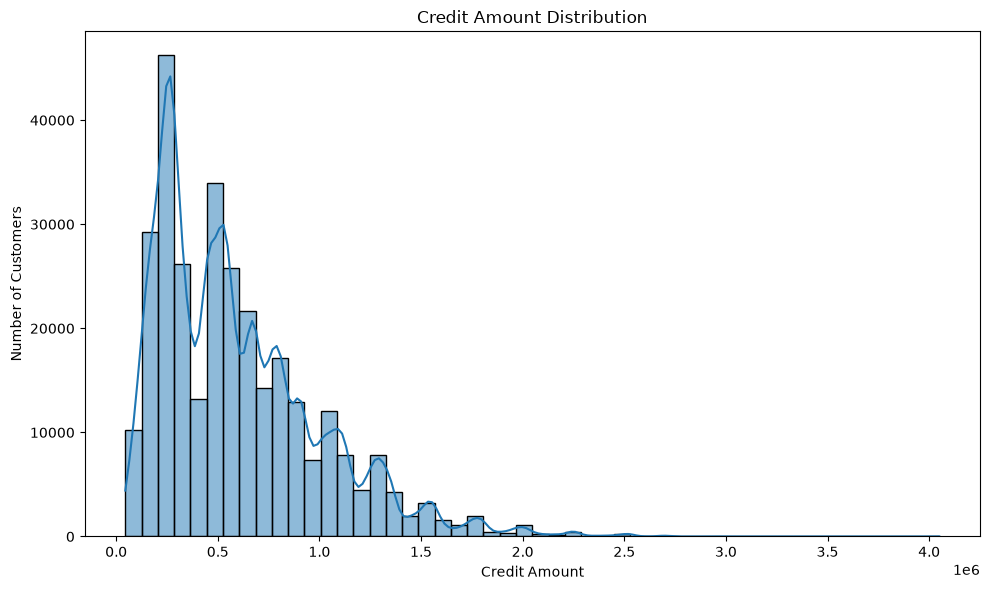

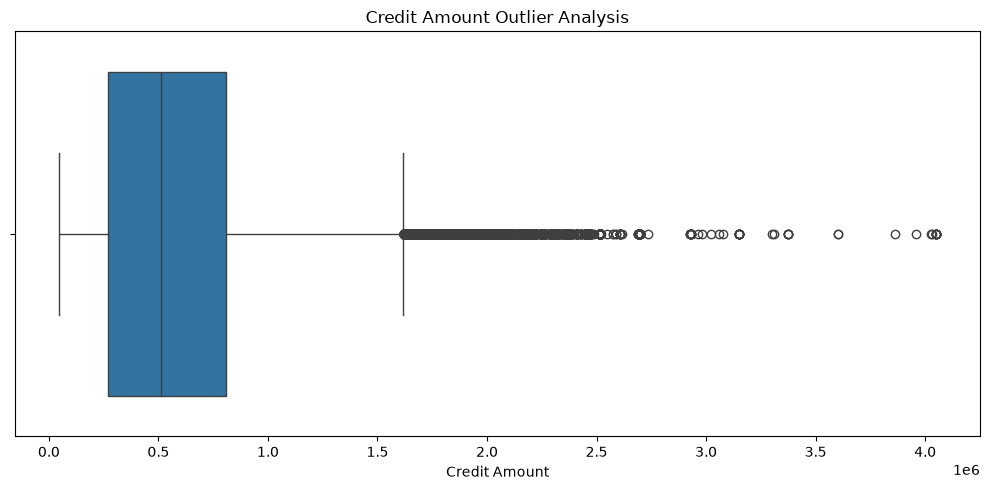

,total_customers,defaulted_customers,target_records,average_credit,average_income,default_percentage
CREDIT_CATEGORY,,,,,,
High Credit,76877,7039,76877,6.475865e+05,175186.187822,9.156185
Low Credit,76878,5585,76878,1.954589e+05,128034.970420,7.264757
Medium Credit,76878,7395,76878,3.881291e+05,153861.616513,9.619137
Very High Credit,76878,4806,76878,1.164930e+06,218108.985530,6.251463


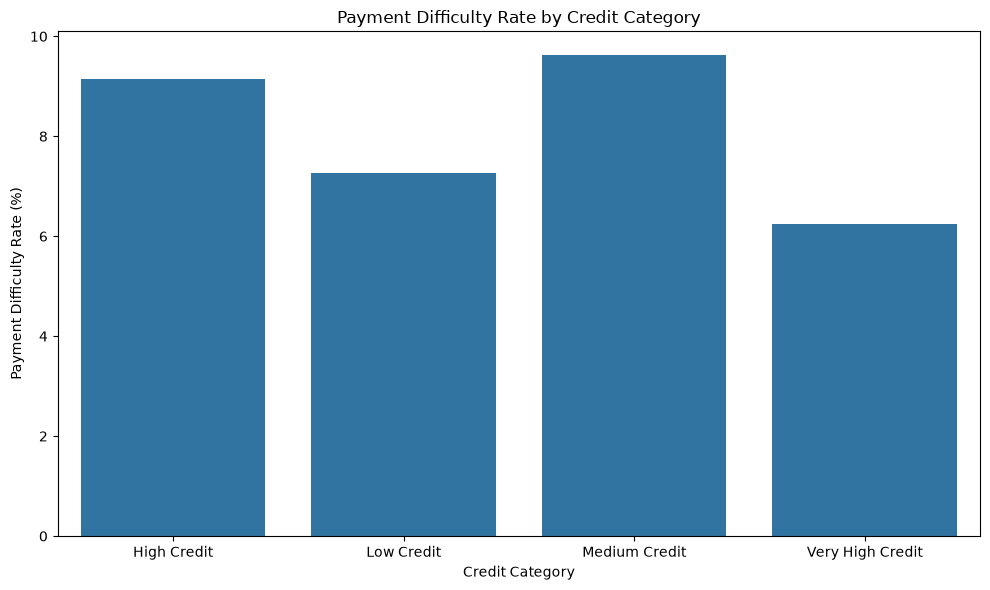

In [28]:
# Credit statistics
print("Average credit:", df["AMT_CREDIT"].mean())
print("Median credit:", df["AMT_CREDIT"].median())
print("Maximum credit:", df["AMT_CREDIT"].max())
print("Minimum credit:", df["AMT_CREDIT"].min())

# Credit distribution
plt.figure(figsize=(10, 6))

sns.histplot(
    data=df,
    x="AMT_CREDIT",
    bins=50,
    kde=True
)

plt.title("Credit Amount Distribution")
plt.xlabel("Credit Amount")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()

# Credit boxplot
plt.figure(figsize=(10, 5))

sns.boxplot(x=df["AMT_CREDIT"])

plt.title("Credit Amount Outlier Analysis")
plt.xlabel("Credit Amount")
plt.tight_layout()
plt.show()

# Create credit amount categories
credit_category = pd.Series(
    index=df.index,
    dtype="object"
)

valid_credit = df["AMT_CREDIT"].notna()

credit_category.loc[valid_credit] = pd.qcut(
    df.loc[valid_credit, "AMT_CREDIT"].rank(method="first"),
    q=4,
    labels=[
        "Low Credit",
        "Medium Credit",
        "High Credit",
        "Very High Credit"
    ]
).astype("object")

df["CREDIT_CATEGORY"] = credit_category

# Credit analysis
credit_analysis = df.groupby(
    "CREDIT_CATEGORY",
    observed=True
).agg(
    total_customers=("SK_ID_CURR", "nunique"),
    defaulted_customers=("TARGET", "sum"),
    target_records=("TARGET", "count"),
    average_credit=("AMT_CREDIT", "mean"),
    average_income=("AMT_INCOME_TOTAL", "mean")
)

credit_analysis["default_percentage"] = (
    credit_analysis["defaulted_customers"]
    / credit_analysis["target_records"]
    * 100
)

display(credit_analysis)

# Payment difficulty by credit category
plt.figure(figsize=(10, 6))

sns.barplot(
    data=credit_analysis.reset_index(),
    x="CREDIT_CATEGORY",
    y="default_percentage"
)

plt.title("Payment Difficulty Rate by Credit Category")
plt.xlabel("Credit Category")
plt.ylabel("Payment Difficulty Rate (%)")
plt.tight_layout()
plt.show()

# Save results
credit_analysis.to_csv(REPORTS_DIR / "credit_analysis.csv")

,TARGET,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,DAYS_BIRTH,DAYS_EMPLOYED
TARGET,1.000000,-0.003982,-0.030369,-0.012817,-0.039645,0.078239,-0.044932
AMT_INCOME_TOTAL,-0.003982,1.000000,0.156870,0.191657,0.159610,0.027261,-0.064223
AMT_CREDIT,-0.030369,0.156870,1.000000,0.770138,0.986968,-0.055436,-0.066838
AMT_ANNUITY,-0.012817,0.191657,0.770138,1.000000,0.775109,0.009445,-0.104332
AMT_GOODS_PRICE,-0.039645,0.159610,0.986968,0.775109,1.000000,-0.053442,-0.064842
DAYS_BIRTH,0.078239,0.027261,-0.055436,0.009445,-0.053442,1.000000,-0.615864
DAYS_EMPLOYED,-0.044932,-0.064223,-0.066838,-0.104332,-0.064842,-0.615864,1.000000


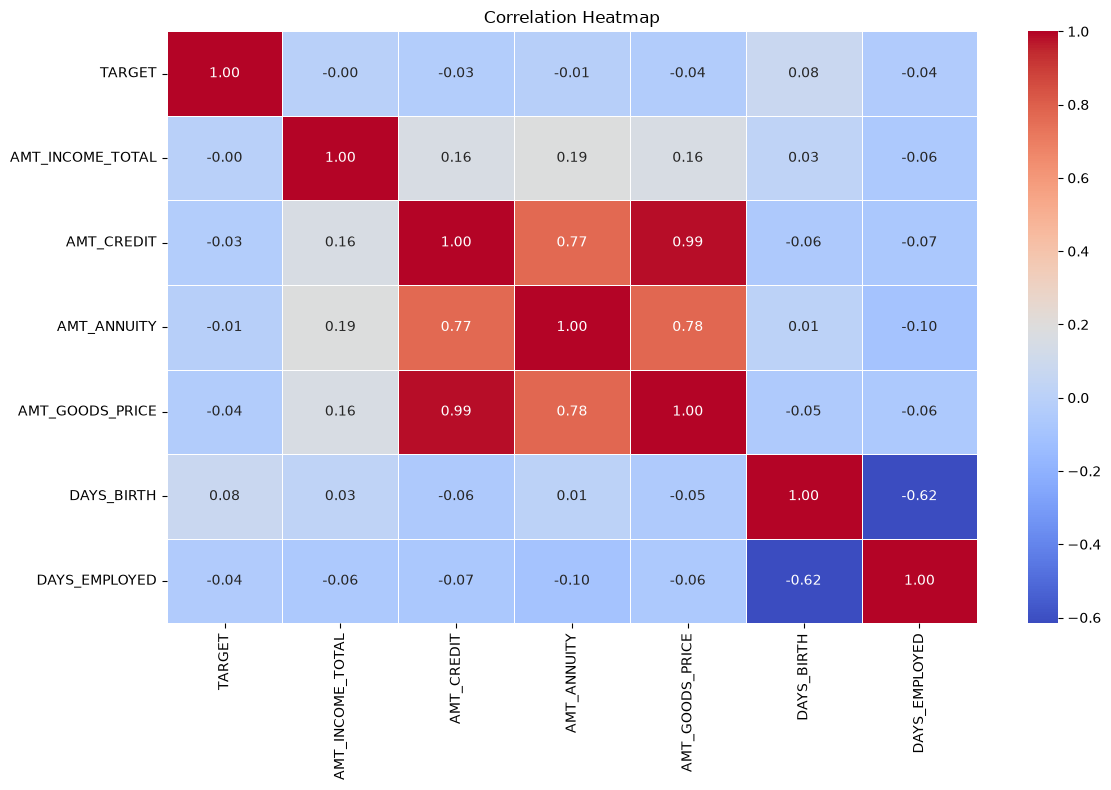

DAYS_BIRTH          0.078239
AMT_INCOME_TOTAL   -0.003982
AMT_ANNUITY        -0.012817
AMT_CREDIT         -0.030369
AMT_GOODS_PRICE    -0.039645
DAYS_EMPLOYED      -0.044932
Name: TARGET, dtype: float64

In [30]:
# Select numerical columns
correlation_columns = [
    "TARGET",
    "AMT_INCOME_TOTAL",
    "AMT_CREDIT",
    "AMT_ANNUITY",
    "AMT_GOODS_PRICE",
    "DAYS_BIRTH",
    "DAYS_EMPLOYED"
]

correlation_df = df[correlation_columns].corr()

# Display correlation matrix
display(correlation_df)

# Correlation heatmap
plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation_df,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

# Correlation with TARGET
target_correlation = (
    correlation_df["TARGET"]
    .drop("TARGET")
    .sort_values(ascending=False)
)

display(target_correlation)

# Save results
correlation_df.to_csv(REPORTS_DIR / "correlation_matrix.csv")
target_correlation.to_csv(
    REPORTS_DIR / "target_correlation.csv"
)

,total_customers,defaulted_customers,target_records,average_income,average_credit,average_annuity,default_percentage
INCOME_SEGMENT,,,,,,,
Low Income,63698,5225,63698,78074.093642,3.872161e+05,18257.664422,8.202769
Medium Income,155898,13326,155898,142968.760787,5.672741e+05,25739.592846,8.547897
High Income,85213,6128,85213,264313.998304,7.988072e+05,35457.107437,7.191391
Very High Income,2702,146,2702,785536.912472,1.123809e+06,51468.400259,5.403405


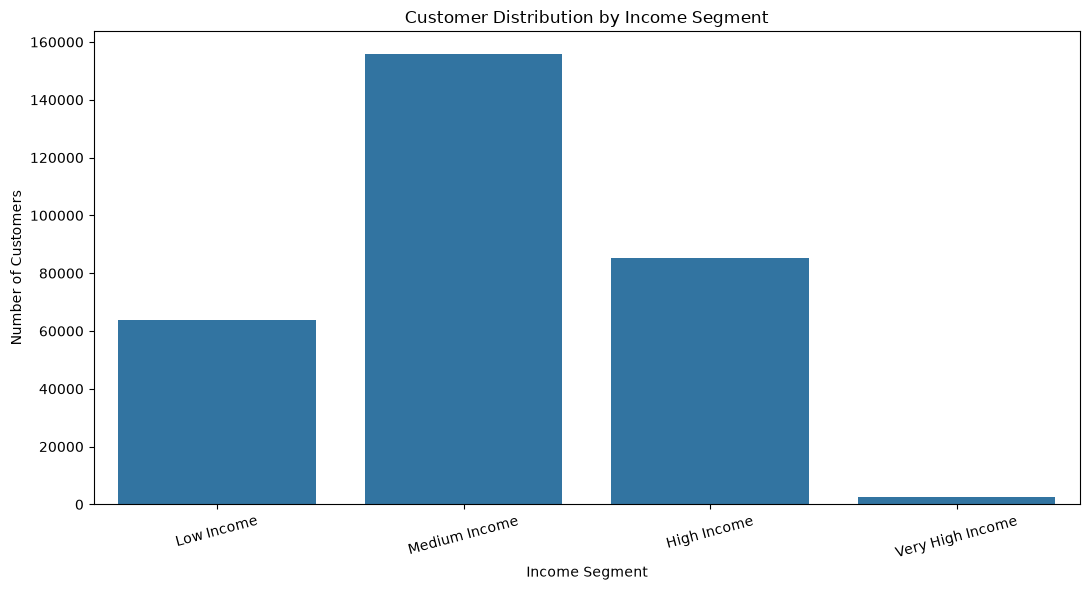

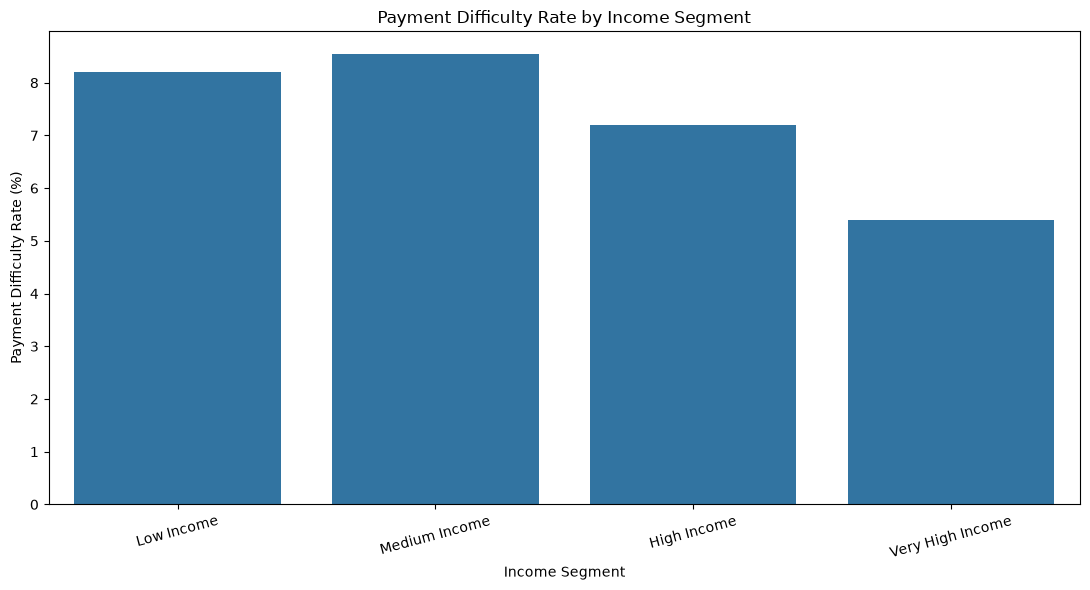

In [32]:
# Create income segments
df["INCOME_SEGMENT"] = pd.cut(
    df["AMT_INCOME_TOTAL"],
    bins=[
        -np.inf,
        100000,
        200000,
        500000,
        np.inf
    ],
    labels=[
        "Low Income",
        "Medium Income",
        "High Income",
        "Very High Income"
    ]
)

# Analyze income segments
income_segmentation = df.groupby(
    "INCOME_SEGMENT",
    observed=True
).agg(
    total_customers=("SK_ID_CURR", "nunique"),
    defaulted_customers=("TARGET", "sum"),
    target_records=("TARGET", "count"),
    average_income=("AMT_INCOME_TOTAL", "mean"),
    average_credit=("AMT_CREDIT", "mean"),
    average_annuity=("AMT_ANNUITY", "mean")
)

income_segmentation["default_percentage"] = (
    income_segmentation["defaulted_customers"]
    / income_segmentation["target_records"]
    * 100
)

display(income_segmentation)

# Visualize segments
plt.figure(figsize=(11, 6))

sns.barplot(
    data=income_segmentation.reset_index(),
    x="INCOME_SEGMENT",
    y="total_customers"
)

plt.title("Customer Distribution by Income Segment")
plt.xlabel("Income Segment")
plt.ylabel("Number of Customers")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

# Compare payment-difficulty rates
plt.figure(figsize=(11, 6))

sns.barplot(
    data=income_segmentation.reset_index(),
    x="INCOME_SEGMENT",
    y="default_percentage"
)

plt.title("Payment Difficulty Rate by Income Segment")
plt.xlabel("Income Segment")
plt.ylabel("Payment Difficulty Rate (%)")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

# Save results
income_segmentation.to_csv(
    REPORTS_DIR / "income_segmentation.csv"
)

In [40]:
eda_columns = [

    "AGE",

    "AGE_GROUP",

    "INCOME_CATEGORY",

    "CREDIT_CATEGORY",

    "INCOME_SEGMENT"

]

# Define processed dataset directory (supports execution from project root or python/ directory)
processed_dir = (
    PROJECT_ROOT / "datasets" / "processed"
    if "PROJECT_ROOT" in globals()
    else (Path("../datasets/processed") if Path("../datasets").exists() else Path("datasets/processed"))
)

# Create directory if it doesn't exist

processed_dir.mkdir(parents=True, exist_ok=True)

# Save enriched dataset

enriched_dataset_path = processed_dir / "application_train_eda.csv"

df.to_csv(

    enriched_dataset_path,

    index=False

)

print("Enriched dataset saved successfully!")

print("File location:", enriched_dataset_path.resolve())


Enriched dataset saved successfully!
File location: /Users/bipulkumar/Desktop/Banking-Financial-Risk-Analytics/datasets/processed/application_train_eda.csv


In [42]:
total_customers = df["SK_ID_CURR"].nunique()

valid_targets = df["TARGET"].notna().sum()

customers_with_payment_difficulties = (
    df["TARGET"] == 1
).sum()

payment_difficulty_rate = (
    customers_with_payment_difficulties / valid_targets * 100
    if valid_targets > 0 else np.nan
)

eda_summary = pd.DataFrame({
    "Metric": [
        "Total Customers",
        "Customers with Payment Difficulties",
        "Payment Difficulty Rate (%)",
        "Average Customer Income",
        "Median Customer Income",
        "Average Credit Amount",
        "Average Customer Age",
        "Missing Income Records",
        "Duplicate Customer IDs"
    ],
    "Value": [
        total_customers,
        customers_with_payment_difficulties,
        round(payment_difficulty_rate, 2),
        round(df["AMT_INCOME_TOTAL"].mean(), 2),
        round(df["AMT_INCOME_TOTAL"].median(), 2),
        round(df["AMT_CREDIT"].mean(), 2),
        round(df["AGE"].mean(), 2),
        df["AMT_INCOME_TOTAL"].isnull().sum(),
        df["SK_ID_CURR"].duplicated().sum()
    ]
})

display(eda_summary)

# Export summary
eda_summary.to_csv(
    REPORTS_DIR / "eda_summary.csv",
    index=False
)

print("\nEDA completed successfully!")
print("Reports saved in:", REPORTS_DIR.resolve())


,Metric,Value
0,Total Customers,307511.00
1,Customers with Payment Difficulties,24825.00
2,Payment Difficulty Rate (%),8.07
3,Average Customer Income,168797.92
4,Median Customer Income,147150.00
5,Average Credit Amount,599026.00
6,Average Customer Age,43.91
7,Missing Income Records,0.00
8,Duplicate Customer IDs,0.00
